## Homework 6

In [34]:
# Import your libraries... 
import pandas as pd
import matplotlib.pyplot as plt

### Part 1: Practice resampling & chart building with Pandas and Matplotlib

In [17]:
# For this assignment, you'll be working with NYC payroll data again. 
# Import it from wherever you stored the data

payroll_data = pd.read_csv('../data/cleaner-payroll-data.csv', low_memory=False)
payroll_data["Base Salary"]= payroll_data["Base Salary"].str.replace("$","").str.replace(",","").str.replace(".00","")
payroll_data["Base Salary"] = payroll_data["Base Salary"].astype(float)
print(len(payroll_data))

552938


Using this data, create an ordered, horizontal bar chart of the top 10 biggest agencies in NYC. 

In [18]:
# Your code here.

payroll_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 552938 entries, 0 to 552937
Data columns (total 17 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Fiscal Year                 552938 non-null  int64  
 1   Payroll Number              552938 non-null  int64  
 2   Agency Name                 552938 non-null  str    
 3   Last Name                   552576 non-null  str    
 4   First Name                  552564 non-null  str    
 5   Mid Init                    321955 non-null  str    
 6   Agency Start Date           552938 non-null  str    
 7   Work Location Borough       552937 non-null  str    
 8   Title Description           552935 non-null  str    
 9   Leave Status as of June 30  552938 non-null  str    
 10  Base Salary                 552938 non-null  float64
 11  Pay Basis                   552938 non-null  str    
 12  Regular Hours               552938 non-null  str    
 13  Regular Gross Paid       

In [19]:
payroll_data["Agency Name"].value_counts().reset_index()

,Agency Name,count
0,DEPT OF ED PEDAGOGICAL,106882
1,DEPT OF ED PER SESSION TEACHER,82883
2,POLICE DEPARTMENT,58617
3,DEPT OF ED PARA PROFESSIONALS,39580
4,BOARD OF ELECTION POLL WORKERS,29915
...,...,...
151,BRONX COMMUNITY BOARD #1,2
152,BRONX COMMUNITY BOARD #12,2
153,BROOKLYN COMMUNITY BOARD #12,2
154,BROOKLYN COMMUNITY BOARD #8,2


Now, create an ordered, horizontal bar chart of the top ten agencies with the highest median base salary.

In [20]:
# Your code here.

payroll_data.groupby(
    ["Agency Name"]
)["Base Salary"].median().reset_index().sort_values(by="Base Salary",ascending=False)

,Agency Name,Base Salary
118,OFFICE OF COLLECTIVE BARGAININ,140000.00
88,FINANCIAL INFO SVCS AGENCY,126952.00
12,BRONX COMMUNITY BOARD #12,115307.00
111,MUNICIPAL WATER FIN AUTHORITY,112604.00
85,DISTRICTING COMMISSION,103750.00
...,...,...
75,DEPT OF PARKS & RECREATION,19.42
68,DEPT OF ED HRLY SUPPORT STAFF,16.52
134,PUBLIC SERVICE CORPS,16.00
125,PERSONNEL MONITORS,15.00


Let's return to our police data to practice resampling. 

In [21]:
# Remember to change the file path to match where your data is stored. 

police_data = pd.read_csv("../data/police-shootings.csv", parse_dates=["date"])
len(police_data)

10430

In [22]:
police_data.head()

,id,date,threat_type,flee_status,armed_with,city,county,state,latitude,longitude,location_precision,name,age,gender,race,race_source,was_mental_illness_related,body_camera,agency_ids
0,3,2015-01-02,point,not,gun,Shelton,Mason,WA,47.246826,-123.121592,not_available,Tim Elliot,53.0,male,A,not_available,True,False,73
1,4,2015-01-02,point,not,gun,Aloha,Washington,OR,45.487421,-122.891696,not_available,Lewis Lee Lembke,47.0,male,W,not_available,False,False,70
2,5,2015-01-03,move,not,unarmed,Wichita,Sedgwick,KS,37.694766,-97.280554,not_available,John Paul Quintero,23.0,male,H,not_available,False,False,238
3,8,2015-01-04,point,not,replica,San Francisco,San Francisco,CA,37.762910,-122.422001,not_available,Matthew Hoffman,32.0,male,W,not_available,True,False,196
4,9,2015-01-04,point,not,other,Evans,Weld,CO,40.383937,-104.692261,not_available,Michael Rodriguez,39.0,male,H,not_available,False,False,473


In [23]:
police_data.info() 

<class 'pandas.DataFrame'>
RangeIndex: 10430 entries, 0 to 10429
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   id                          10430 non-null  int64         
 1   date                        10430 non-null  datetime64[us]
 2   threat_type                 10362 non-null  str           
 3   flee_status                 8939 non-null   str           
 4   armed_with                  10219 non-null  str           
 5   city                        10356 non-null  str           
 6   county                      5739 non-null   str           
 7   state                       10430 non-null  str           
 8   latitude                    9290 non-null   float64       
 9   longitude                   9289 non-null   float64       
 10  location_precision          9290 non-null   str           
 11  name                        10112 non-null  str           
 12  a

Remember in class, we learned that resampling requires several basic steps:

1. Make sure that Pandas is reading in your date column as a date. If it's not, convert it to datetime.
2. Create a new dataframe with your date column as your index
3. Resample the data over the time interval of your choosing.

With this in mind, resample the data over a monthly period and plot it in a line chart.

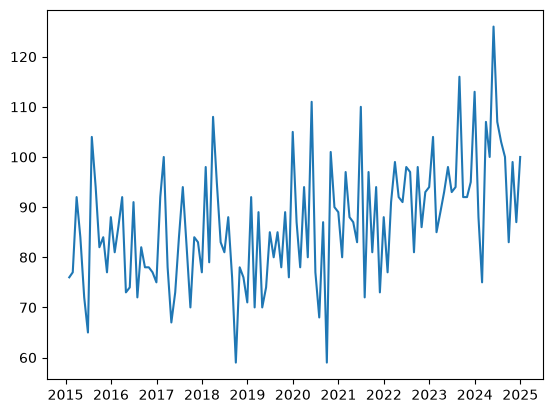

In [43]:
# Your code here.

police_dated = police_data.set_index("date")
police_tally = police_dated.resample('ME')['id'].count()## ME is month, month is depreciated. W is week, D is day ? 


plt.plot(police_tally)


Now create an ordered bar chart of total police killings by year. Put the two charts side by side using the strategy we reviewed in class.

In [53]:
police_bar = police_dated["state"].value_counts().reset_index()
police_bar

,state,count
0,CA,1405
1,TX,1010
2,FL,672
3,AZ,461
4,GA,393
5,CO,375
6,NC,310
7,OH,305
8,TN,293
9,WA,277


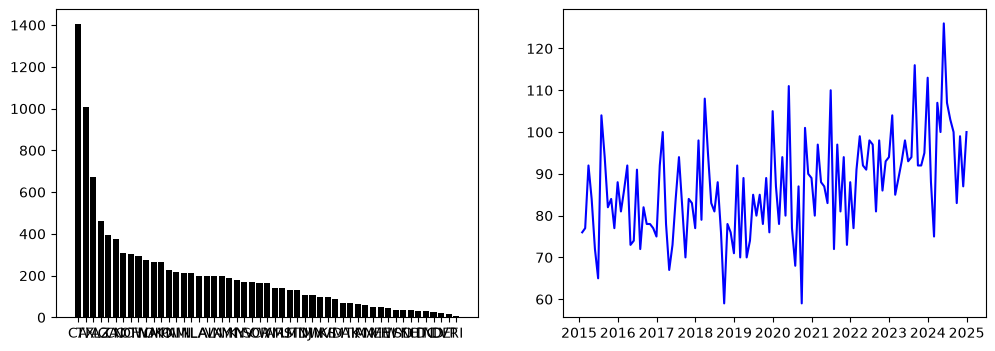

In [55]:
# Your code here


fig, ax = plt.subplots(1,2)

fig.set_size_inches(12,4) 
ax[0].bar(police_bar["state"], police_bar['count'],color="black")
ax[1].plot(police_tally, color="blue")

#police_tally.plot(kind="bar",x="id", y="date", color="#000000")

### Part 2: Assignment 1

Come to class having made significant progress on your first assignment. Please come prepared to share your progress with your classmates and ask them/me any questions you might have for feedback. Part of classtime will be devoted to working on your original data analysis.